# Vision Transformers

## 1. How do we obtain the embeddings from the images?

In [202]:
from torchvision.datasets import CIFAR10

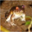

In [203]:
dataset = CIFAR10(root="data", train=True, download=False)
image, label = dataset[0]
image

In [204]:
label

6

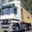

In [205]:
image, label = dataset[1]
image

In [206]:
image.size

(32, 32)

Let's try with a bigger image. :)

In [207]:
N = 512 # size of the image

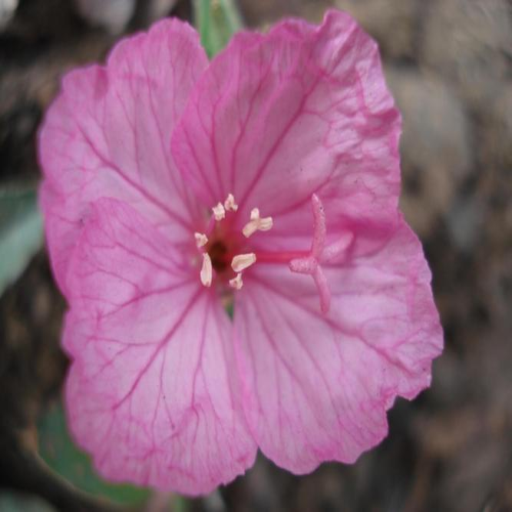

In [208]:
from torchvision.datasets import Flowers102
from torchvision import transforms

dataset = Flowers102(
    root="data",
    split="train",
    download=False,
    transform=transforms.Resize((N, N))
)

image, label = dataset[2]
image

In [209]:
image.size

(512, 512)

### Step 1: Split the original images into smaller patches

In [210]:
import numpy as np
import matplotlib.pyplot as plt

In [211]:
image_arr = np.array(image)
image_arr.shape

(512, 512, 3)

In [212]:
K = 128 # size of a patch

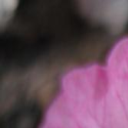

In [213]:
Image.fromarray(image_arr[0:K, 0:K]) # <=> Image.fromarray(image_arr[0:K, 0:K, :])

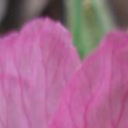

In [214]:
Image.fromarray(image_arr[0:K, K:2*K])

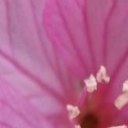

In [215]:
Image.fromarray(image_arr[K:2*K, K:2*K])

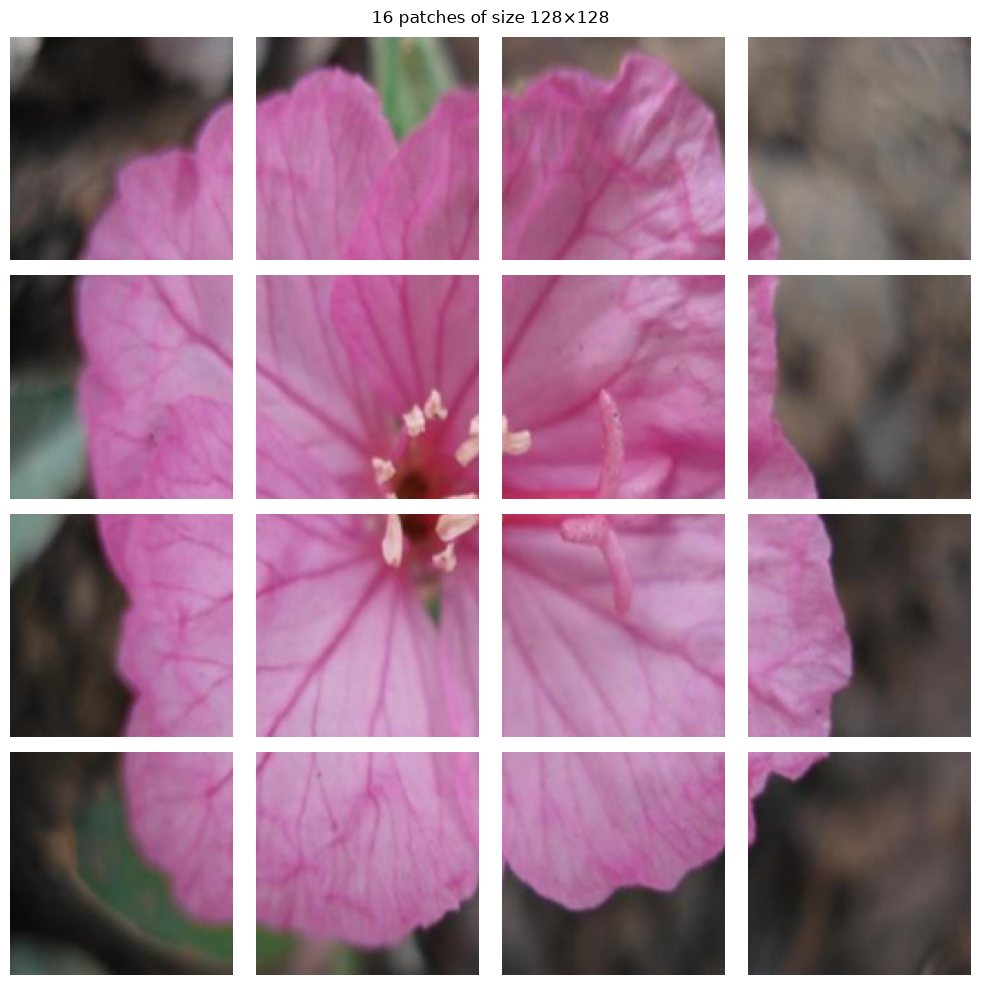

In [216]:
N_PATCHES = N // K

patches = []
fig, axes = plt.subplots(N_PATCHES, N_PATCHES, figsize=(10, 10))

for i in range(N_PATCHES):
    for j in range(N_PATCHES):
        patch = image_arr[i*K:(i+1)*K, j*K:(j+1)*K]

        axes[i, j].imshow(patch)
        axes[i, j].axis("off")

        patches.append(patch)

patches = np.array(patches)

plt.suptitle(f"{N_PATCHES * N_PATCHES} patches of size {K}×{K}")
plt.tight_layout()
plt.show()

### Step 2: Flatten the patches

In [217]:
patches.shape

(16, 128, 128, 3)

In [218]:
assert N_PATCHES * N_PATCHES == patches.shape[0]

flatten_patches = patches.reshape(patches.shape[0], -1)
flatten_patches.shape

(16, 49152)

In [219]:
flatten_patches

array([[162, 162, 162, ..., 196, 134, 176],
       [118, 115, 122, ..., 181,  90, 142],
       [104,  87,  80, ..., 165,  79, 126],
       ...,
       [199, 148, 189, ...,  49,  48,  44],
       [193, 130, 181, ...,  52,  52,  50],
       [197, 135, 186, ...,  56,  46,  45]],
      shape=(16, 49152), dtype=uint8)

## Step 3: Apply linear projection

This is the first learnable layer. We project our patches into a fixed embedding size *emb_dim*. 

In [220]:
emb_dim = 384 # embeddings size

In [221]:
patch_dim = flatten_patches.shape[-1]
patch_dim

49152

In [222]:
import torch
import torch.nn as nn

X = torch.tensor(flatten_patches, dtype=torch.float32)

projection = nn.Linear(patch_dim, emb_dim)
embeddings = projection(X)

print(embeddings.shape)

torch.Size([16, 384])


## FINAL STEP: Write the PatchEmbedding class
- We simulated the steps to obtain embeddings for ViT starting from a single image.
- Do not forget that in the pipeline, there is a batch of samples at each step $\implies$ a new size B at the front of the tensors. :)

In [259]:
from torchvision.datasets import Flowers102
from torchvision import transforms
from torch.utils.data import DataLoader

N = 512 # IMAGE_SIZE
K = 128 # PATCH_SIZE
batch_size = 8

dataset = Flowers102(
    root="data",
    split="train",
    download=False,
    transform=transforms.Compose([
        transforms.Resize((N, N)),
        transforms.ToTensor()
    ])
)

dataloader = DataLoader(
    dataset,
    batch_size=batch_size,
    shuffle=True
)

images, labels = next(iter(dataloader))

print(images.shape)
print(labels.shape)

torch.Size([8, 3, 512, 512])
torch.Size([8])


### IMPLEMENTATION 1: Using stack

In [288]:
import torch
import torch.nn as nn

class PatchEmbeddingStack(nn.Module):
    def __init__(self, 
                image_size,
                patch_size, 
                in_channel,
                emb_dim):
        super().__init__()

        assert image_size % patch_size == 0

        self.image_size = image_size
        self.patch_size = patch_size
        self.in_channel = in_channel
        self.emb_dim = emb_dim
        
        self.num_patches_per_dim = (image_size // patch_size) # -> total number of patches = P = self.num_patches_per_dim * self.num_patches_per_dim

        patch_dim = patch_size * patch_size * in_channel # we need this for projection layer

        self.projection = nn.Linear(patch_dim, emb_dim)

    def forward(self, x):
        # x: (B, C, H, W)
        
        B, C, H, W = x.shape

        # STEP 1 - Split image into patches
        patches = [] # [patch1, patch2, patch3 ... patchP] -> P * patch: [B, C, K, K]
        K = self.patch_size
        for i in range(self.num_patches_per_dim):
            for j in range(self.num_patches_per_dim):
                patch = x[:, :, i*K:(i+1)*K, j*K:(j+1)*K]
                patches.append(patch)

        '''
        patches = [
            tensor_0,    # (B, C, K, K)  => B x (C x K x K)
            tensor_1,    # (B, C, K, K)
            tensor_2,    # (B, C, K, K)
            ...
            tensor_P-1    # (B, C, K, K)
        ]
        '''
        # patches : P x B x C x K x K  =>  B x P x PATCH_DIM
        # PATCH_DIM = C * K * K
        patches = torch.stack(patches, dim=1)

        # STEP 2 - Flatten Patches
        # flatten_patches = patches.reshape(B, -1, C * K * K)
        flatten_patches = patches.flatten(start_dim=2)
    
        # STEP 3 - Linear Projection
        return self.projection(flatten_patches)

In [289]:
pe = PatchEmbeddingStack(N, K, 3, 384)
out = pe(images)

In [290]:
out.shape

torch.Size([8, 16, 384])

#### torch.stack explained

In [ ]:
# [10, 20, 30], [100, 200, 300] -> instead of 3d images...we have just a point a single dim for image: 3 pixels ... so we have two images (a batch size of 2). 

In [291]:
import torch

patches = [
    torch.tensor([10, 100]),   # Patch 0 from both images
    torch.tensor([20, 200]),   # Patch 1 from both images
    torch.tensor([30, 300])    # Patch 2 from both images
]

In [292]:
patches_dim0 = torch.stack(patches, dim=0)
patches_dim0

tensor([[ 10, 100],
        [ 20, 200],
        [ 30, 300]])

In [257]:
patches_dim0.shape

torch.Size([3, 2])

In [258]:
patches_dim1 = torch.stack(patches, dim=1)
patches_dim1

tensor([[ 10,  20,  30],
        [100, 200, 300]])

### IMPLEMENTATION 2: Using unfold

#### Understanding how unfold works

In [264]:
x = torch.tensor([1, 2, 3, 4, 5, 6, 7, 8])

In [268]:
# It's basically a sliding window :)

# dimension = which dimension to operate on
# size = sliding window size
# step = sliding window step
x.unfold(dimension=0, size=3, step=2)

tensor([[1, 2, 3],
        [3, 4, 5],
        [5, 6, 7]])

In [276]:
# Now let's suppose we have an image: 8x8 size
x = torch.arange(64).reshape(8, 8)

In [277]:
x

tensor([[ 0,  1,  2,  3,  4,  5,  6,  7],
        [ 8,  9, 10, 11, 12, 13, 14, 15],
        [16, 17, 18, 19, 20, 21, 22, 23],
        [24, 25, 26, 27, 28, 29, 30, 31],
        [32, 33, 34, 35, 36, 37, 38, 39],
        [40, 41, 42, 43, 44, 45, 46, 47],
        [48, 49, 50, 51, 52, 53, 54, 55],
        [56, 57, 58, 59, 60, 61, 62, 63]])

In [278]:
# Let's divide it into 4x4 patches... => total of patches
patches = x.unfold(dimension=0, size=4, step=4)
patches

tensor([[[ 0,  8, 16, 24],
         [ 1,  9, 17, 25],
         [ 2, 10, 18, 26],
         [ 3, 11, 19, 27],
         [ 4, 12, 20, 28],
         [ 5, 13, 21, 29],
         [ 6, 14, 22, 30],
         [ 7, 15, 23, 31]],

        [[32, 40, 48, 56],
         [33, 41, 49, 57],
         [34, 42, 50, 58],
         [35, 43, 51, 59],
         [36, 44, 52, 60],
         [37, 45, 53, 61],
         [38, 46, 54, 62],
         [39, 47, 55, 63]]])

In [ ]:
# what do we observe in here? 

In [279]:
patches.shape

torch.Size([2, 8, 4])

In [282]:
patches

tensor([[[ 0,  8, 16, 24],
         [ 1,  9, 17, 25],
         [ 2, 10, 18, 26],
         [ 3, 11, 19, 27],
         [ 4, 12, 20, 28],
         [ 5, 13, 21, 29],
         [ 6, 14, 22, 30],
         [ 7, 15, 23, 31]],

        [[32, 40, 48, 56],
         [33, 41, 49, 57],
         [34, 42, 50, 58],
         [35, 43, 51, 59],
         [36, 44, 52, 60],
         [37, 45, 53, 61],
         [38, 46, 54, 62],
         [39, 47, 55, 63]]])

In [281]:
# Let's divide it into 4x4 patches... => total of patches
patches_after = patches.unfold(dimension=1, size=4, step=4)
patches_after

tensor([[[[ 0,  1,  2,  3],
          [ 8,  9, 10, 11],
          [16, 17, 18, 19],
          [24, 25, 26, 27]],

         [[ 4,  5,  6,  7],
          [12, 13, 14, 15],
          [20, 21, 22, 23],
          [28, 29, 30, 31]]],


        [[[32, 33, 34, 35],
          [40, 41, 42, 43],
          [48, 49, 50, 51],
          [56, 57, 58, 59]],

         [[36, 37, 38, 39],
          [44, 45, 46, 47],
          [52, 53, 54, 55],
          [60, 61, 62, 63]]]])

In [293]:
patches_after.shape

torch.Size([2, 2, 4, 4])

In [317]:
import torch
import torch.nn as nn

class PatchEmbeddingUnfold(nn.Module):
    def __init__(self, 
                image_size,
                patch_size, 
                in_channel,
                emb_dim):
        super().__init__()

        assert image_size % patch_size == 0

        self.image_size = image_size
        self.patch_size = patch_size
        self.in_channel = in_channel
        self.emb_dim = emb_dim
        
        self.num_patches_per_dim = (image_size // patch_size) # -> total number of patches = P = self.num_patches_per_dim * self.num_patches_per_dim

        patch_dim = patch_size * patch_size * in_channel # we need this for projection layer

        self.projection = nn.Linear(patch_dim, emb_dim)

    def forward(self, x):
        # x: (B, C, H, W)
        
        B, C, H, W = x.shape
        #print(x.shape)

        # STEP 1 - Split image into patches
        K = self.patch_size
        
        x_height_patches = x.unfold(dimension=2, size=K, step=K)
        #print(x_height_patches.shape) # B x C x (N/K) x W x K
        
        patches = x_height_patches.unfold(dimension=3, size=K, step=K)
        #print(patches.shape) # B x C x (N / K) x (N / K) x K x K

        patches_linearized = patches.flatten(start_dim=2, end_dim=3)
        #print(patches_linearized.shape)
        
        patches_permuted = patches_linearized.permute(0, 2, 1, 3, 4)
        #print(patches_permuted.shape)
        
        # STEP 2 - Flatten Patches
        flatten_patches = patches_permuted.flatten(start_dim=2)
        
        # STEP 3 - Linear Projection
        return self.projection(flatten_patches)

In [318]:
pe = PatchEmbeddingUnfold(N, K, 3, 384)
out = pe(images)

In [319]:
out.shape

torch.Size([8, 16, 384])

### IMPLEMENTATION 3: Using conv2D

In [326]:
import torch
import torch.nn as nn

class PatchEmbeddingConv(nn.Module):
    def __init__(self, 
                image_size,
                patch_size, 
                in_channel,
                emb_dim):
        super().__init__()

        assert image_size % patch_size == 0

        self.image_size = image_size
        self.patch_size = patch_size
        self.in_channel = in_channel
        self.emb_dim = emb_dim

        self.conv = nn.Conv2d(in_channels=in_channel, 
                              out_channels=emb_dim, 
                              kernel_size=patch_size,
                              stride=patch_size)

    def forward(self, x):
        # x: (B, C, H, W)
        
        x_out = self.conv(x)
        # print(x_out.shape) # B x E x (H / K) x (W / K) = B x E x Pd x Pd
        
        x_out_flatten = x_out.flatten(start_dim=2)
        #print(x_out_flatten.shape) # B x E x P

        x_permuted = x_out_flatten.permute(0, 2, 1)
        
        return x_permuted

In [329]:
pe = PatchEmbeddingConv(N, K, 3, 384)
out = pe(images)
out.shape

torch.Size([8, 16, 384])

Does Conv2d gives the same result? Proof in a mathematical manner. :)

## 2. CLS token and Positional Embeddings

What is a CLS token and why do we need it?

Transformer will produce one output per vector per patch... So at the end, you will still have $X = B \times P \times E$. 

What is more is that each vector contains new information from other patches beause of the self-attention mechanism used inside the transformer.

How do we get to the classification head from that?

$P_1 P_2, ..., P_E$  outputs after transformer

**OPTION A: Average Pooling**

We compute the average of the outputs and then we put that into the linear layer.


**OPTION B: Flattening**

We concatenate the outputs and we get a layer with $P \times E$ size. Through a linear layer with $O$ - outputs (number of classes), we'll get $O \cdot P \cdot E$ params, which can be a lot.


**OPTION C: New [CLS] token**

A new token that is trained through self-attention by iterating with all the other patches. We only connect this token's output with the linear layer, so only $O \cdot E$ params. 

Questions:
1. Why not picking a random output $P_i$? Or a fixed patch output $P_0$?

At the end, it is an architectural choice to introduce this CLS which act as a learned image-level representation.

As a result: CLS token is an additional token used besides the tokens obtained from patches. By adding it, instead of P tokens (one embedding for each patch), we will have P + 1 tokens... $X = B \times (P + 1) \times E$

#### torch.expand?

In [338]:
x = torch.arange(8).reshape(1, 1, 8)
x

tensor([[[0, 1, 2, 3, 4, 5, 6, 7]]])

In [340]:
x.expand(4, -1, -1)

tensor([[[0, 1, 2, 3, 4, 5, 6, 7]],

        [[0, 1, 2, 3, 4, 5, 6, 7]],

        [[0, 1, 2, 3, 4, 5, 6, 7]],

        [[0, 1, 2, 3, 4, 5, 6, 7]]])

In [346]:
x.expand(-1, 4, -1)

tensor([[[0, 1, 2, 3, 4, 5, 6, 7],
         [0, 1, 2, 3, 4, 5, 6, 7],
         [0, 1, 2, 3, 4, 5, 6, 7],
         [0, 1, 2, 3, 4, 5, 6, 7]]])

Why not using repeat?

In [352]:
class TokenPositionEmbedding(nn.Module):
    def __init__(self, num_patches, emb_dim):
        super().__init__()

        self.num_patches = num_patches
        self.emb_dim = emb_dim

        # LEARNABLE CLS token
        # 1 shared parameter, 1 token, emb_dim features
        self.cls_token = nn.Parameter(
            torch.zeros(1, 1, emb_dim)
        )
        nn.init.normal_(self.cls_token, mean=0.0, std=0.02)

        # EMBEDDINGS for positions
        # num_patches + 1 includes the CLS token
        self.pos_embedding = nn.Parameter(
            torch.zeros(1, num_patches + 1, emb_dim)
        )
        nn.init.normal_(self.pos_embedding, mean=0.0, std=0.02)

    def forward(self, x):
        # x: B x P x E
        B, P, E = x.shape

        assert P == self.num_patches
        assert E == self.emb_dim

        # Step 1: use the same CLS token for each image
        cls_each_image = self.cls_token.expand(B, -1, -1)

        # Step 2: concatenate CLS at the beginning
        x = torch.cat([cls_each_image, x], dim=1)

        # Step 3: add positional embeddings
        # Broadcasting across the batch dimension :)
        x = x + self.pos_embedding

        # B x (P + 1) x E
        return x

In [353]:
images.shape

torch.Size([8, 3, 512, 512])

In [356]:
pe = PatchEmbeddingConv(N, K, 3, 384)
out_pe = pe(images)
out_pe.shape

torch.Size([8, 16, 384])

In [357]:
tpe = TokenPositionEmbedding(out.shape[1], E)
out_tpe = tpe(out)
out_tpe.shape

torch.Size([8, 17, 384])